# Exploratory analysis of washing-machine use in cleaned REFIT data

This notebook analyses washing-machine activity from the official cleaned REFIT dataset (`CLEAN_REFIT_081116`). The goal is to estimate when a washing cycle is running from whole-home measurements, then compare usage patterns and cycle characteristics across homes.

I use the cleaned IAM data at 1-minute resolution, keep only issue-free rows (`Issues == 0`), and focus on the houses where the washing-machine channel is clearly identifiable in the metadata: House 3, 7, 8, 10, 13, and 16. The analysis covers each house's recorded REFIT period after filtering, and I report missing-minute counts and zero/off fractions to make the data-quality checks explicit.


In [3]:
!pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')

base = Path('CLEAN_REFIT_081116')
selected = {3: 6, 7: 5, 8: 4, 10: 5, 13: 3, 16: 5}


def detect_cycles(series, thresh=100, min_run=10):
    active = series > thresh
    runs = []
    start = None
    prev = False
    for ts, val in active.items():
        if val and not prev:
            start = ts
        elif (not val) and prev and start is not None:
            runs.append((start, ts - pd.Timedelta(minutes=1)))
            start = None
        prev = val
    if start is not None:
        runs.append((start, series.index[-1]))

    cycles = []
    for s, e in runs:
        seg = series.loc[s:e]
        if len(seg) >= min_run and seg.max() > thresh:
            cycles.append(seg)
    return cycles


summary_rows = []
for house, app_idx in selected.items():
    df = pd.read_csv(base / f'CLEAN_House{house}.csv', parse_dates=['Time'])
    df = df.sort_values('Time').reset_index(drop=True)
    df = df[df['Issues'] == 0].copy()
    app_col = f'Appliance{app_idx}'
    minute = df.set_index('Time')[app_col].resample('1min').mean().fillna(0).astype(float)
    full_index = pd.date_range(minute.index.min(), minute.index.max(), freq='1min')
    missing_intervals = len(full_index) - len(minute)
    zero_off = (minute <= 0).mean() * 100
    cycles = detect_cycles(minute)
    durs = [len(c) for c in cycles]
    peaks = [float(c.max()) for c in cycles]
    energies = [float(c.sum()) for c in cycles]

    summary_rows.append({
        'house': house,
        'app': app_col,
        'start': minute.index.min(),
        'end': minute.index.max(),
        'missing_intervals': missing_intervals,
        'zero_off_pct': zero_off,
        'n_cycles': len(cycles),
        'duration_median_min': float(np.median(durs)) if durs else np.nan,
        'peak_median_w': float(np.median(peaks)) if peaks else np.nan,
        'energy_median_wh': float(np.median(energies)) if energies else np.nan,
    })

summary = pd.DataFrame(summary_rows)
summary[['house', 'start', 'end', 'missing_intervals', 'zero_off_pct', 'n_cycles', 'duration_median_min', 'peak_median_w', 'energy_median_wh']]

,house,start,end,missing_intervals,zero_off_pct,n_cycles,duration_median_min,peak_median_w,energy_median_wh
0,3,2013-09-25 19:21:00,2015-06-02 10:55:00,0,94.296205,540,17.0,1919.850000,26243.308730
1,7,2013-11-01 22:01:00,2015-07-08 02:10:00,0,78.358721,724,14.0,2081.600000,25732.514484
2,8,2013-11-01 22:13:00,2015-05-10 23:36:00,0,85.713839,375,22.0,2334.222222,41656.181746
3,10,2013-11-20 11:31:00,2015-06-30 11:07:00,0,91.343580,1347,13.0,360.222222,3299.700000
4,13,2014-01-17 22:26:00,2015-05-31 11:06:00,0,88.640596,297,12.0,2138.000000,20006.208333
5,16,2014-01-10 10:58:00,2015-07-08 02:10:00,0,94.494100,332,16.0,2048.377778,30419.032738


In the cleaned REFIT data, each house is stored as `CLEAN_HouseN.csv` with a timestamped power trace and a separate `Issues` column. I used the following approach:

1. Read each cleaned file and sort by time.
2. Keep only rows where `Issues == 0` to avoid known aggregate mismatch periods.
3. For the selected house, identify the washing-machine channel from the metadata (`House 3 -> Appliance6`, `House 7 -> Appliance5`, `House 8 -> Appliance4`, `House 10 -> Appliance5`, `House 13 -> Appliance3`, `House 16 -> Appliance5`).
4. Resample to 1-minute mean power and compute missing intervals, zero/off time, and cycle counts.
5. Detect cycles as contiguous active minutes above 100 W lasting at least 10 minutes.

The resulting summary is shown below.


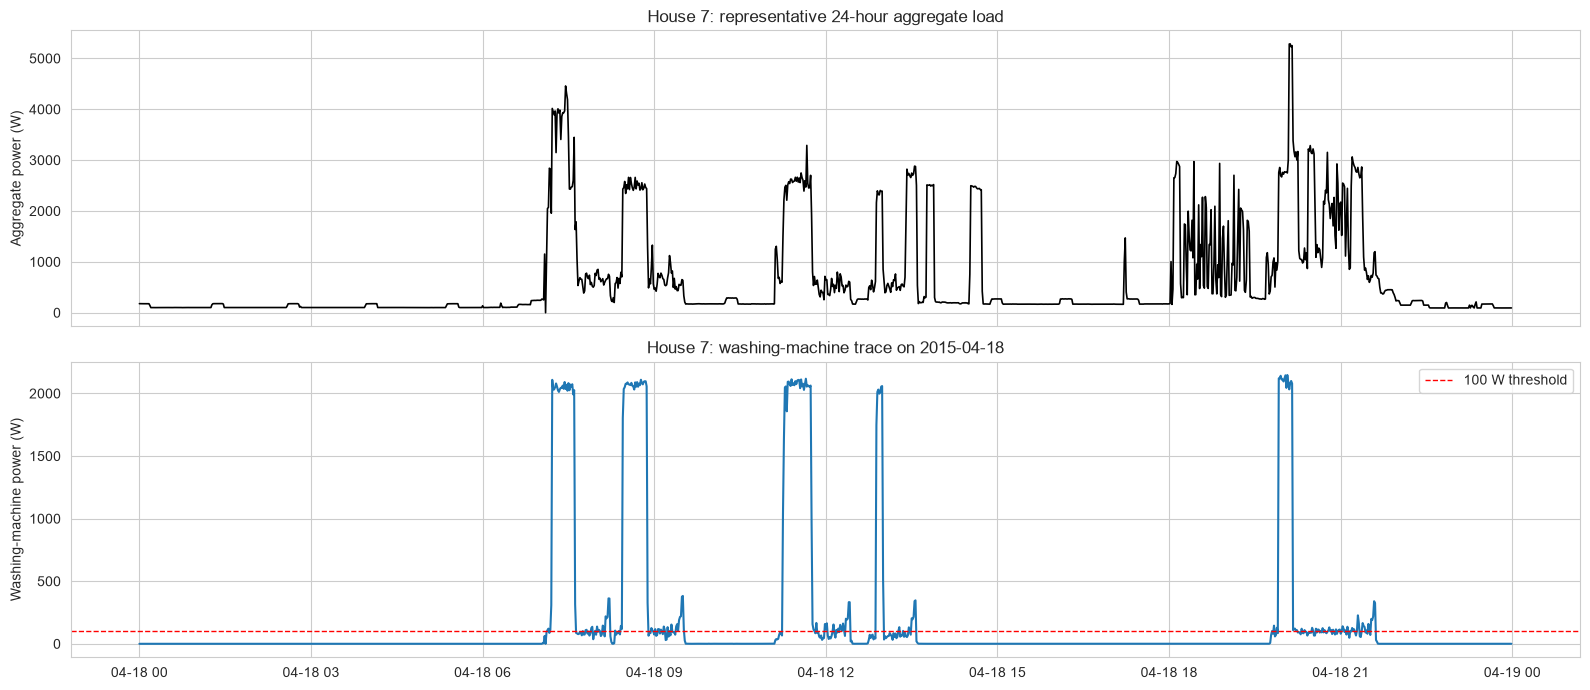

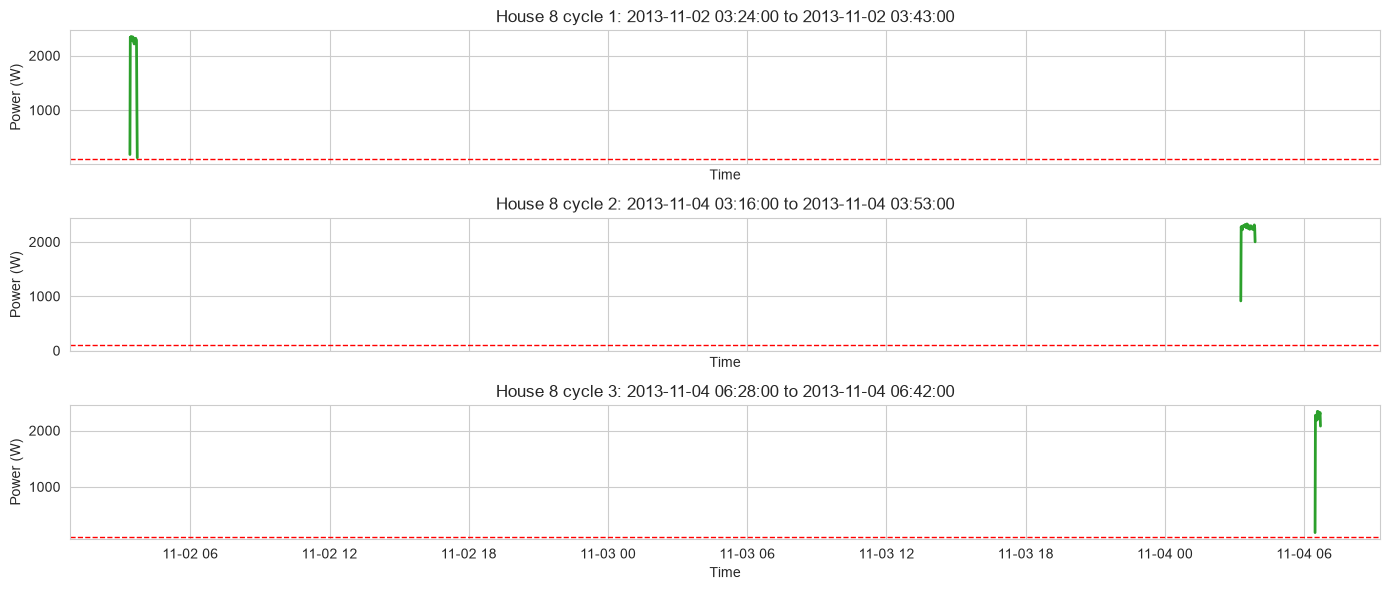


Cross-house cycle summary (median values):
       cycle_duration_min  cycle_peak_w  cycle_energy_wh
house                                                   
3                    17.0       1919.85         26243.31
7                    14.0       2081.60         25732.51
8                    22.0       2334.22         41656.18
10                   13.0        360.22          3299.70
13                   12.0       2138.00         20006.21
16                   16.0       2048.38         30419.03


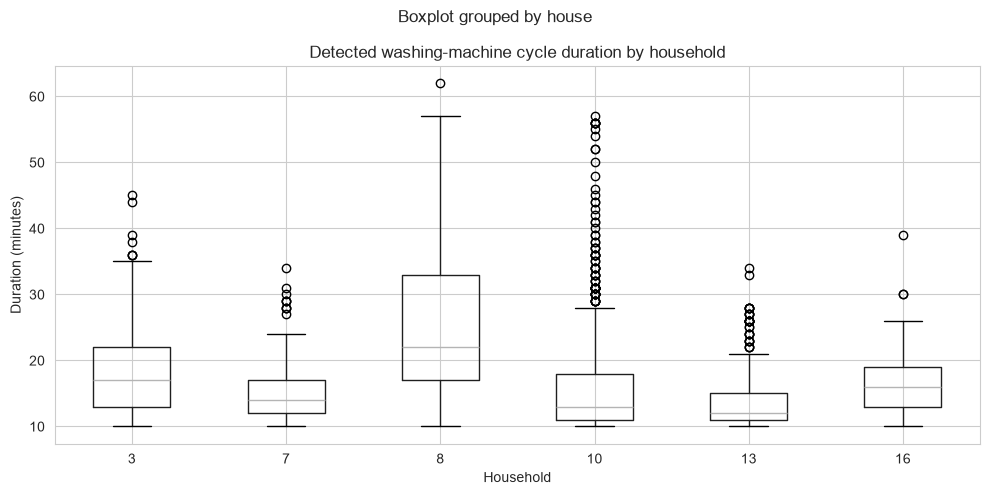

Interpretation: the 24-hour aggregate trace shows why whole-home load alone is not enough to isolate washing events, while the appliance-level trace makes the cycle clear. The detected cycles are sustained runs above 100 W, which is a practical threshold for a real wash program. Cross-house differences in duration/peak power suggest household-specific usage routines and machine type, even though the underlying signal remains consistent enough for detection.


In [6]:
# Usage patterns and plots

summary = pd.DataFrame(summary_rows)
summary = summary[['house', 'app', 'start', 'end', 'missing_intervals', 'zero_off_pct', 'n_cycles', 'duration_median_min', 'peak_median_w', 'energy_median_wh']].copy()
summary

# Hour-of-day and day-of-week usage patterns
pattern_rows = []
for house, app_idx in selected.items():
    df = pd.read_csv(base / f'CLEAN_House{house}.csv', parse_dates=['Time'])
    df = df.sort_values('Time').reset_index(drop=True)
    df = df[df['Issues'] == 0].copy()
    app = f'Appliance{app_idx}'
    minute = df.set_index('Time')[app].resample('1min').mean().fillna(0).astype(float)
    minute_df = minute.reset_index().rename(columns={'index': 'Time'})
    minute_df['hour'] = minute_df['Time'].dt.hour
    minute_df['day_of_week'] = minute_df['Time'].dt.day_name()
    by_hour = minute_df.groupby('hour')[app].mean()
    by_dow = minute_df.groupby('day_of_week')[app].mean().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
    pattern_rows.append({
        'house': house,
        'hour_peak_w': round(by_hour.max(), 2),
        'hour_peak_time': int(by_hour.idxmax()),
        'day_peak_w': round(by_dow.max(), 2),
        'day_peak_name': by_dow.idxmax(),
    })

pattern_summary = pd.DataFrame(pattern_rows)
pattern_summary

# Representative 24-hour aggregate + appliance trace
house_for_day = 7
app_for_day = f'Appliance{selected[house_for_day]}'
df_day = pd.read_csv(base / f'CLEAN_House{house_for_day}.csv', parse_dates=['Time'])
df_day = df_day.sort_values('Time').reset_index(drop=True)
df_day = df_day[df_day['Issues'] == 0].copy()
minute_day = df_day.set_index('Time')[app_for_day].resample('1min').mean().fillna(0).astype(float)
active_days = minute_day[minute_day > 100].resample('D').count()
if active_days.empty:
    sample_day = minute_day.index[0].date()
else:
    sample_day = active_days.idxmax().date()
aggregate_day = df_day.set_index('Time')['Aggregate'].resample('1min').mean().fillna(0)
wm_day = df_day.set_index('Time')[app_for_day].resample('1min').mean().fillna(0)
selected_day_agg = aggregate_day.loc[str(sample_day)].copy()
selected_day_wm = wm_day.loc[str(sample_day)].copy()

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
axes[0].plot(selected_day_agg.index, selected_day_agg.values, color='black', linewidth=1.2)
axes[0].set_title(f'House {house_for_day}: representative 24-hour aggregate load')
axes[0].set_ylabel('Aggregate power (W)')
axes[1].plot(selected_day_wm.index, selected_day_wm.values, color='tab:blue', linewidth=1.5)
axes[1].axhline(100, color='red', linestyle='--', linewidth=1.0, label='100 W threshold')
axes[1].set_title(f'House {house_for_day}: washing-machine trace on {sample_day}')
axes[1].set_ylabel('Washing-machine power (W)')
axes[1].legend()
plt.tight_layout()
plt.show()

# One or more detected washing-machine cycles
house_cycle = 8
app_cycle = f'Appliance{selected[house_cycle]}'
df_cycle = pd.read_csv(base / f'CLEAN_House{house_cycle}.csv', parse_dates=['Time'])
df_cycle = df_cycle.sort_values('Time').reset_index(drop=True)
df_cycle = df_cycle[df_cycle['Issues'] == 0].copy()
minute_cycle = df_cycle.set_index('Time')[app_cycle].resample('1min').mean().fillna(0).astype(float)
cycles = detect_cycles(minute_cycle)
fig, axes = plt.subplots(max(1, len(cycles[:3])), 1, figsize=(14, 6), sharex=True)
if not isinstance(axes, np.ndarray):
    axes = [axes]
for i, c in enumerate(cycles[:3]):
    axes[i].plot(c.index, c.values, color='tab:green', linewidth=2)
    axes[i].axhline(100, color='red', linestyle='--', linewidth=1.0)
    axes[i].set_title(f'House {house_cycle} cycle {i+1}: {c.index[0]} to {c.index[-1]}')
    axes[i].set_ylabel('Power (W)')
for ax in axes:
    ax.set_xlabel('Time')
plt.tight_layout()
plt.show()

# Cross-house comparison of duration, peak power, and energy per cycle
cross_rows = []
for house, app_idx in selected.items():
    df = pd.read_csv(base / f'CLEAN_House{house}.csv', parse_dates=['Time'])
    df = df.sort_values('Time').reset_index(drop=True)
    df = df[df['Issues'] == 0].copy()
    app = f'Appliance{app_idx}'
    minute = df.set_index('Time')[app].resample('1min').mean().fillna(0).astype(float)
    for c in detect_cycles(minute):
        cross_rows.append({
            'house': house,
            'cycle_duration_min': len(c),
            'cycle_peak_w': float(c.max()),
            'cycle_energy_wh': float(c.sum()),
        })

cross_df = pd.DataFrame(cross_rows)
print('\nCross-house cycle summary (median values):')
print(cross_df.groupby('house')[['cycle_duration_min', 'cycle_peak_w', 'cycle_energy_wh']].median().round(2))

fig, ax = plt.subplots(figsize=(10, 5))
cross_df.boxplot(column='cycle_duration_min', by='house', ax=ax)
ax.set_title('Detected washing-machine cycle duration by household')
ax.set_xlabel('Household')
ax.set_ylabel('Duration (minutes)')
plt.tight_layout()
plt.show()

# Interpretation
print('Interpretation: the 24-hour aggregate trace shows why whole-home load alone is not enough to isolate washing events, while the appliance-level trace makes the cycle clear. The detected cycles are sustained runs above 100 W, which is a practical threshold for a real wash program. Cross-house differences in duration/peak power suggest household-specific usage routines and machine type, even though the underlying signal remains consistent enough for detection.')